# Statistikkprosjekt: Klyngeanalyse av Adelie pingviner

### Navn: 
##### Eirin Iversen, Johanna Andersen, Karina Barstad, Lucy Herud-Thomassen, Meenakshi Jayachandran

### Problemstilling:

Kan K-means-klyngeanalyse identifisere grupper av Adelie pingviner basert på kroppsmål, og hvordan varierer disse gruppene med hensyn til kroppsmasse, kjønn og øytilhørighet?

I denne notebooken undersøker jeg om Adelie pingviner kan deles inn i grupper ut fra kroppsmål ved hjelp av K-means-klyngeanalyse. Jeg bruker nebblengde, nebdybde og svømmeluffelengde for å danne klynger. Deretter sammenligner jeg klynger med kroopsmasse, kjønn og hvilken øy pingvinene kommer fra. Disse tre siste variablene brukes ikkr for å danne klyngene.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans 

sns.set_theme(style="whitegrid")

In [2]:
# Laster inn datasettet
penguins = sns.load_dataset("penguins")

adelie_penguins = penguins[penguins["species"] == "Adelie"].copy()

variabler = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
]

penguins datasettet som lastes inn med seaborn bibloteket er det datasettet analysen skal bruke. Analysen er avgrenset til arten Adelie. Det gjør at sammenligningene gjelderindivider innen samme art, ikke forskjeller mellom pingvinarter

In [3]:
# fjerner observasjoner med manglende verdier
adelie_data = adelie_penguins.dropna(subset = variabler + ["sex", "body_mass_g", "island"]).copy()

x = adelie_data[variabler].copy()
print("Antall observasjoner:", x.shape[0])

Antall observasjoner: 146


## Valg og data filtrering:

Klyngende dannes fra *bill_length_mm* (nebblengde), *bill_depth_mm* (nebdybde) og *flipper_length_mm* (svømmeluffelengde). Observasjoner som har manglende verdiser i disse målingene eller i *sex*, *body_mass_g* eller *island* fjernes. Etter å fjernet disse observasjonene, er det bare 146 igjen. Kroppsmasse, kjønn og øy holdes utenfor selve klyngeinndelingen og brukes senere til tolkning.
(resultatene fra denne analysen gjelder bare de 146 komplette observasjonene)

In [4]:
# de tre variablene er standardisert
# hver variabel får gjennomsnitt 0 og standardavvik 1
scaler = StandardScaler()
x_standardisert = scaler.fit_transform(x)

De tre kroppsmålene har forskjellige variasjonsbredder. Standarisering gir hver variabel gjennomsnitt 0 og standardavvik 1, slik at en variabel ikke får utforholdsmessig stor innflytelse på avstandsberegningene bare på grunnav skalaen.

## Albuemetoden
#### *Hvor synker kurven mest? Er K = 2 et rimelig valg?*

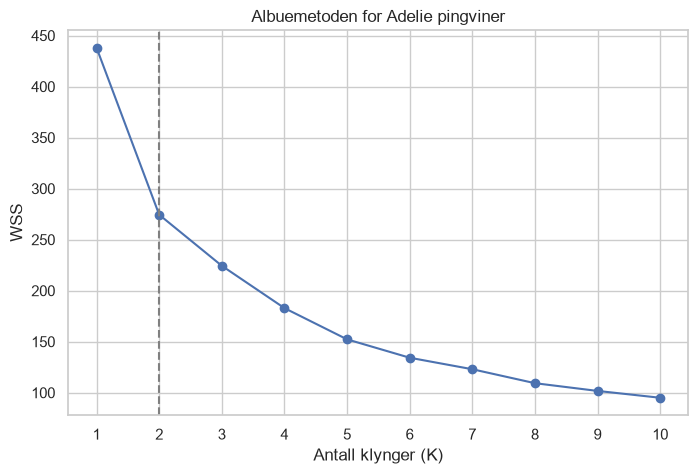

In [5]:
# albuemetoden for å undersøke antall klynger
plt.figure(figsize=(8, 5))

wss = []

for k in range(1, 11):
    modell_k = KMeans(
        n_clusters = k,
        random_state = 0,
        n_init = 10
    )

    modell_k.fit(x_standardisert)
    wss.append(modell_k.inertia_)

plt.plot(range(1, 11), wss, marker = "o")
plt.title("Albuemetoden for Adelie pingviner")
plt.xlabel("Antall klynger (K)")
plt.ylabel("WSS")
plt.xticks(range(1,11))
plt.axvline(x = 2, color = "grey", linestyle = "--")
plt.show()

### Tolkning av albuemetoden
WSS måler samlet variasjon i klyngene. I grafen fra koden synker WSS kraftig fra **K = 1 til K = 2**, deretter synker den mer gradvis. Det er ingen helt tydelig albue ved K = 2. Likevel brukes det to klynger fordi det gir en enkel og tolkbar inndeling som kna sammenlignes med kjønn. Dette er et timelig valg, men ikke et entydig optimalt antall klynger.

## K-means-klyngeanalyse
#### *Hvor mange observasjoner havner i hver klynge?*

In [6]:
# K-means klyngeanalyse
modell = KMeans(
    n_clusters = 2,
    random_state = 0,
    n_init = 10
)

modell.fit(x_standardisert)

adelie_data["klynge"] = modell.labels_
print(adelie_data["klynge"].value_counts().sort_index())

klynge
0    52
1    94
Name: count, dtype: int64


### Resultat:
Analysen gir **52 pingviner i klynge 0** OG **94 pingviner i klynge 1**; til sammen ble det 146 observasjoner. Klyngene er derfor ikke like store. Resultatet si fordelignen alene sier ikke hva klyngene representerer; derfor undersøker jeg gjennomsnittlige kroppsmål videre.

## Sammenligne kroppsmål og kroppsmasse
#### *Hvilken klynge har størst kropsmål?*

In [7]:
# undersøke gjennomsnittlige kroppsmål og kroppsmasse
print("\nGjennomsnittlige kroppsmål og kroppsmasse:")
gjennomsnitt = adelie_data.groupby("klynge")[variabler + ["body_mass_g"]].mean()
print(gjennomsnitt.round(2))


Gjennomsnittlige kroppsmål og kroppsmasse:
        bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
klynge                                                               
0                40.95          19.36             195.50      4087.50
1                37.65          17.79             187.12      3495.21


### Resultat: gjennomsnitt per klynge

| Variabel | Klynge 0 | Klynge 1 |
|---|---:|---:|
| Nebblengde (mm) | 40,95 | 37,65 |
| Nebbdybde (mm) | 19,36 | 17,79 |
| Svømmeluffelengde (mm) | 195,50 | 187,12 |
| Kroppsmasse (g) | 4087,50 | 3495,21 |

Klynge 0 har større gjennomsnittlige kroppsmål enn klynge 1. Den har også høyere gjennomsnittlige kroppsmasse, selv om kroppsmasse IKKE ble brukt til å lage klyngene. Forskjellen i gjennomsnittlig kroppsmasse er ca. 592 gram

## Kroppsmasse etter kjønn og klynge
#### *Er kroppsmasse forskjellig mellom klyngene også innen hvert kjønn?*

In [8]:
# gjennomsnittlig kroppsmasse fordelt på klynge og kjønn
print("\nGjennomsnittlig kroppsmasse etter klynge og kjønn:")

masse_kjonn = adelie_data.groupby(
    ["klynge", "sex"]
)["body_mass_g"].mean()
print(masse_kjonn.round(2))


Gjennomsnittlig kroppsmasse etter klynge og kjønn:
klynge  sex   
0       Female    3533.33
        Male      4121.43
1       Female    3361.79
        Male      3884.38
Name: body_mass_g, dtype: float64



### Resultat: kroppsmasse innen hvert kjønn

| Kjønn | Klynge 0 | Klynge 1 |
|---|---:|---:|
| Hunner | 3533,33 g | 3361,79 g |
| Hanner | 4121,43 g | 3884,38 g |

Kroppsmasse er høyere i klynge 0 også når jeg sammenmligner innen hvert kjønn. **NB!** Det er bare 3 hunner i klynge 0, så gjennomsnittet for denne undergruppen må tolkes forsiktig.


## Krystabell: klynge og kjønn
#### *Ser det ut til å være sammenheng mellom kjønn og klyngetilhørighet?*

In [9]:
# krysstabell som viser hvordan klynger fordeler seg basert på kjønn
print("\nKrystabell: Klynge og kjønn")
tabell_kjonn = pd.crosstab(
    adelie_data["klynge"],
    adelie_data["sex"]
)
print(tabell_kjonn)


Krystabell: Klynge og kjønn
sex     Female  Male
klynge              
0            3    49
1           70    24



### Resultat: klynge og kjønn

| Klynge | Hunner | Hanner |
|---|---:|---:|
| 0 | 3 | 49 |
| 1 | 70 | 24 |

I klynge 0 er ca. 94% hanner, mens ca. 74% i klynge 1 er hunner. Klyngene samsvarer dermed i stor grad med kjønn, men ikke helt perfekt. Dette er interessant fordi kjønn ikke var med som en variabel i K-means-modellen. Analsen viser dermed en sammenheng, ikke at kjønn er bestemt av klyngetilhørigheten.

## Krystabell: klynge og øy
#### *Er noen øyer overrepresentert i bestemte klynger*

In [10]:
# krysstabell som viser hvordan klynger fordeler seg basert på øy
print("\nKrystabell: Klynge og øy")
tabell_oy = pd.crosstab(
    adelie_data["klynge"],
    adelie_data["island"]
)
print(tabell_oy)


Krystabell: Klynge og øy
island  Biscoe  Dream  Torgersen
klynge                          
0           17     14         21
1           27     41         26


### Resultat: klynge og øy
Krysstabellen viser antall ingviner fra Biscoe, Dream og Torgersen i hver klynge. For å sammenligne øyfordelingen så rettferdig som mulig, bruker jeg prossentandelene innen hver klynge. De tre øyene er representert i begge klyngene, så det er ikke en fullstendig geografisk oppdeling. 

## Kjønn, øy og klynge samlet
#### *Er fordelignen ulik for hunner og hanner på de tre øyene?*

In [11]:
# undersøker klyngefordeling ettter kjønn og øy
tabell = pd.crosstab(
    index = [adelie_data["sex"], adelie_data["island"]],
    columns = adelie_data["klynge"]
)
print("\nKlyngefordeling etter kjønn og øy: ")
print(tabell)


Klyngefordeling etter kjønn og øy: 
klynge             0   1
sex    island           
Female Biscoe      1  21
       Dream       0  27
       Torgersen   2  22
Male   Biscoe     16   6
       Dream      14  14
       Torgersen  19   4


### Resultat: kjønn, øy og klynge

| Kjønn | Øy | Klynge 0 | Klynge 1 |
|---|---|---:|---:|
| Hunn | Biscoe | 1 | 21 |
| Hunn | Dream | 0 | 27 |
| Hunn | Torgersen | 2 | 22 |
| Hann | Biscoe | 16 | 6 |
| Hann | Dream | 14 | 14 |
| Hann | Torgersen | 19 | 4 |

Nesten alle hunner ligger i klynge 1, uavhengig av øy (70 av 73). For hannene varierer fordelignen mer. På Dream er hannene likt fordelt mellom klyngene, mens haner fra Biscoe og Torgeresn oftere havner i klynge 0. Dette kan antyde på at det er en sammenheng emllom øy og klyngefordeling blant hannen, men resultatet viser ikke en årsakssammenheng.

## Prosentfordeling av øyer
#### *Hvilken øy har størst andel i hver klynge?*

In [12]:
# prosentvis fordeling av øyer innen hver klynge
print("\nProsetvis øyfordeling innen hver klynge:")
prosent_oy = pd.crosstab(
    adelie_data["klynge"],
    adelie_data["island"],
    normalize="index"
) * 100
print(prosent_oy.round(1))


Prosetvis øyfordeling innen hver klynge:
island  Biscoe  Dream  Torgersen
klynge                          
0         32.7   26.9       40.4
1         28.7   43.6       27.7



### Resultat: prosentvis øyfordeling innen hver klynge

| Øy | Klynge 0 | Klynge 1 |
|---|---:|---:|
| Biscoe | 32,7 % | 28,7 % |
| Dream | 26,9 % | 43,6 % |
| Torgersen | 40,4 % | 27,7 % |

Dream utgjør en større andel av klynge 1, mens Torgeresn utgjør en større andel av klynge 0. Forskjellene er mindre tydeligere enn kjønnsforskjellene. 

## Spredningsdiagram: Klynger
#### *Hvor tydelig skiller klyngene seg i nebblengse og nebbdybde?*

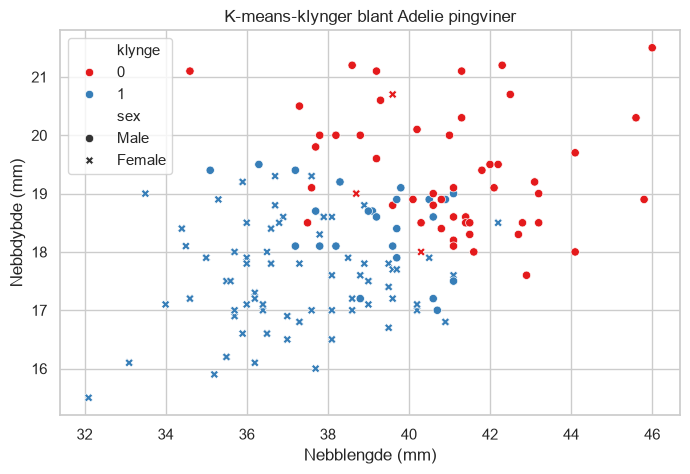

In [13]:
# spredningdiagram fordelt på klynger
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data = adelie_data,
    x = "bill_length_mm",
    y = "bill_depth_mm",
    hue = "klynge",
    style = "sex",
    palette = "Set1"
)

plt.title("K-means-klynger blant Adelie pingviner")
plt.xlabel("Nebblengde (mm)")
plt.ylabel("Nebbdybde (mm)")
plt.show()

Spredningsdiagramet viesr hvordan de to K-means-klyngene fordeler seg etter nebblende og nebbdybde. Modellen brukte også svømmeluffelengde, som ikke vises på aksene. Derfor kan ikke all informasjon som bestemte klyngene ses i denne figuren.

## Spredningsdiagram: Kjønn
#### *Ligger mønsteret for kjønn på mønsteret for klynger?*

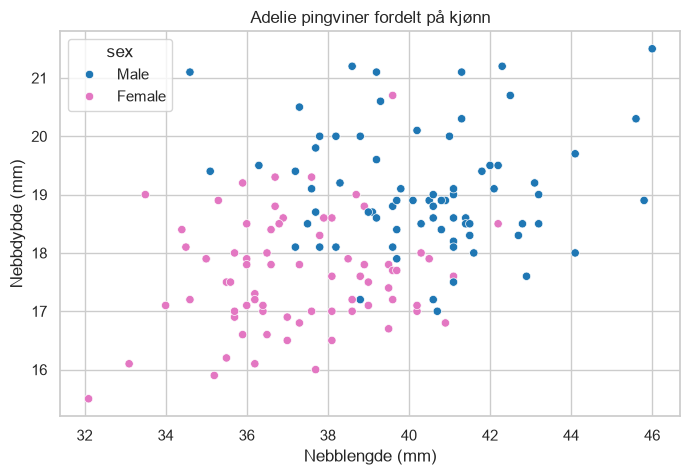

In [14]:
# spredningsdiagram fordelt på kjønn
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data = adelie_data,
    x = "bill_length_mm",
    y = "bill_depth_mm",
    hue = "sex",
    palette = {
      "Male": "tab:blue",
      "Female": "tab:pink",
    }
)

plt.title("Adelie pingviner fordelt på kjønn")
plt.xlabel("Nebblengde (mm)")
plt.ylabel("Nebbdybde (mm)")
plt.show()

Fordelignen etter kjønn kan sammenlignes visuelt med klyngeplottet. Den tydelige kjønnsforskjellen i krysstabellen tyder på at kroppsmålee som brukes i K-means også henger sammen med kjønn, men det finnes overlapp mellom gruppene.

## Spredningsdiagram: Øy
#### *Er det tydelige grupper etter øy, eller overlapper punktene?*

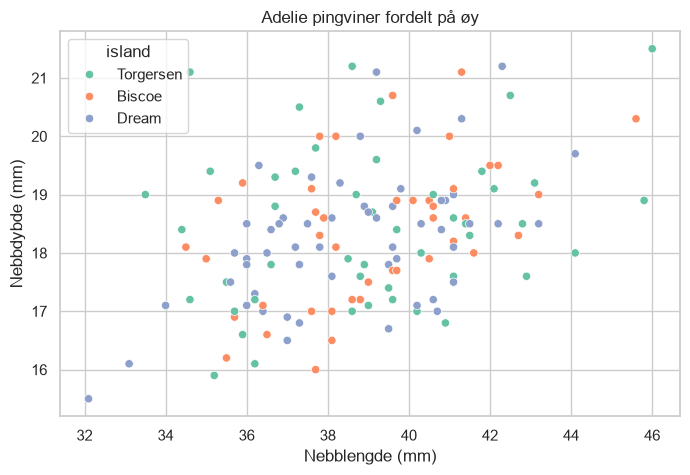

In [15]:
# spredningsdiagram fordelt på øy
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data = adelie_data,
    x = "bill_length_mm",
    y = "bill_depth_mm",
    hue = "island",
    palette = "Set2"
)

plt.title("Adelie pingviner fordelt på øy")
plt.xlabel("Nebblengde (mm)")
plt.ylabel("Nebbdybde (mm)")
plt.show()

Punktene fra Biscoe, Bream og Torgeresn overlapper betydelig. Dette støtter at øytilhørighet har en svakere sammenheng med klyngene enn kjønn.

## Boksplott: Kroppsmasse
##### *Hvordan varierer median og spredning i kroppsmasse mellom klyngene?*

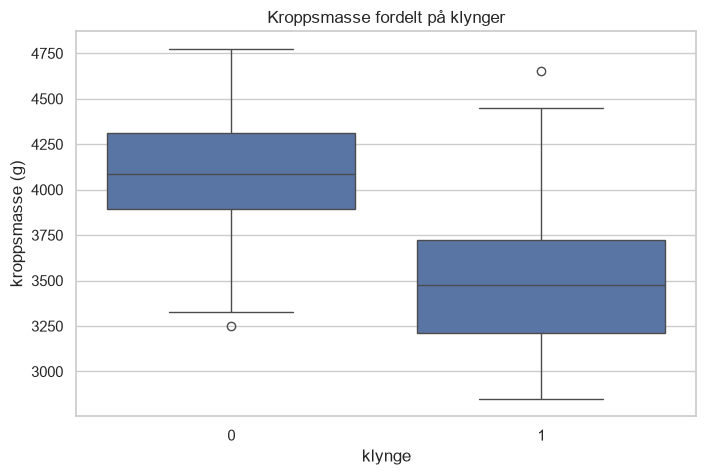

In [16]:
#kroppsmasse i hver klynge
plt.figure(figsize=(8, 5))

sns.boxplot(
    data = adelie_data,
    x = "klynge",
    y = "body_mass_g"
)

plt.title("Kroppsmasse fordelt på klynger")
plt.xlabel("klynge")
plt.ylabel("kroppsmasse (g)")
plt.show()

Kroppsmasse ligger generelt høyere i klynge 0 enn i klynge 1. Gjennomsnittet er 4087.50 gram i klynge 0 og 3495.21 gram i klynge 1. Forskjellen er ca. 592 gram. Boksplottet viser også fordeling og spredning; gjennomsnittene kommer fra tabellen over og er ikke nødvendigvis de horisontale linjene i boksene (viser median).